# CSE457 – XỬ LÝ ÂM THANH VÀ TIẾNG NÓI
## BÁO CÁO THỰC HÀNH LAB 4: TỔNG HỢP TIẾNG NÓI (TEXT-TO-SPEECH)
### Từ Ghép nối (Concatenative) & Unit Selection đến Tham số HMM và TTS Học sâu (Neural TTS)
---
| Thông tin | Chi tiết |
| :--- | :--- |
| **Họ và tên sinh viên** | **Dương Tiến Đạt** |
| **Mã số sinh viên (MSSV)** | **2251172268** |
| **Lớp học phần** | CSE457 – Xử lý âm thanh và tiếng nói |
| **Case Study** | Hệ thống thông báo xếp hàng miền hẹp (Queue Calling TTS) |
| **Yêu cầu giọng nói** | Chuyển đổi văn bản sang tiếng nói **siêu tự nhiên**, mượt mà, đúng thanh điệu |

**Kiến trúc tổng thể của hệ thống Text-to-Speech:**
```
Text Input ──> Text Normalization ──> Phonetic / Unit Selection ──> Prosody / Acoustic Backend ──> Waveform Vocoder
```
> Notebook này được thiết kế để có thể **chạy lại 100% tự động từ đầu đến cuối**, tích hợp sẵn Audio Player và biểu đồ khoa học trực quan.


## 0. Cài đặt môi trường và Thư viện cần thiết

In [1]:
import os, sys, time, math, glob
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown

from lab4_text_norm import normalize_queue_text, tokens_to_unit_ids
from lab4_utils import load_audio, match_rms, calc_rms, compute_log_spec, plot_waveform_and_spectrogram
from lab4_concat import synthesize_concatenative, get_unit_path
from lab4_prosody import estimate_f0_autocorr, track_f0_contour
from lab4_hmm import generate_trajectories, synthesize_source_filter_vocoder
from lab4_neural import synthesize_neural

print('✓ Tất cả các thư viện đã được nạp thành công!')


✓ Tất cả các thư viện đã được nạp thành công!


## 1. Chuẩn hóa văn bản và Khởi tạo Unit Inventory (Phần A)

### 1.1 Nguyên lý Text Normalization trong miền hẹp
Văn bản đầu vào của hệ thống xếp hàng gồm chữ số và từ ngữ viết hoa/thường:  
- `"Mời khách hàng số 23 đến quầy 5."` -> `['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']`
- Các chữ số được tách và đọc tuần tự theo số đếm chuẩn tiếng Việt.

### 1.2 Thiết kế Unit Inventory
- Tổng cộng 16 từ vựng cơ sở: `mời`, `khách`, `hàng`, `số`, `không` đến `chín`, `đến`, `quầy`.
- Mỗi từ có **2 candidates** (`_01` và `_02`) với sắc thái và tốc độ khác nhau để kiểm thử Unit Selection.
- Đều được chuẩn hóa ở $F_s = 16,000$ Hz, mono, 16-bit PCM và $RMS = 0.08$.


Tổng số unit trong inventory: 32 files WAV


,unit_id,label,ascii,candidate,speaker,duration_s,rms,path
0,moi_01,mời,moi,1,vi-VN-HoaiMyNeural,0.384,0.08,units/moi_01.wav
1,moi_02,mời,moi,2,vi-VN-NamMinhNeural,0.384,0.08,units/moi_02.wav
2,khach_01,khách,khach,1,vi-VN-HoaiMyNeural,0.192,0.08,units/khach_01.wav
3,khach_02,khách,khach,2,vi-VN-NamMinhNeural,0.192,0.08,units/khach_02.wav
4,hang_01,hàng,hang,1,vi-VN-HoaiMyNeural,0.352,0.08,units/hang_01.wav
5,hang_02,hàng,hang,2,vi-VN-NamMinhNeural,0.320,0.08,units/hang_02.wav
6,so_01,số,so,1,vi-VN-HoaiMyNeural,0.320,0.08,units/so_01.wav
7,so_02,số,so,2,vi-VN-NamMinhNeural,0.320,0.08,units/so_02.wav
8,khong_01,không,khong,1,vi-VN-HoaiMyNeural,0.288,0.08,units/khong_01.wav
9,khong_02,không,khong,2,vi-VN-NamMinhNeural,0.288,0.08,units/khong_02.wav


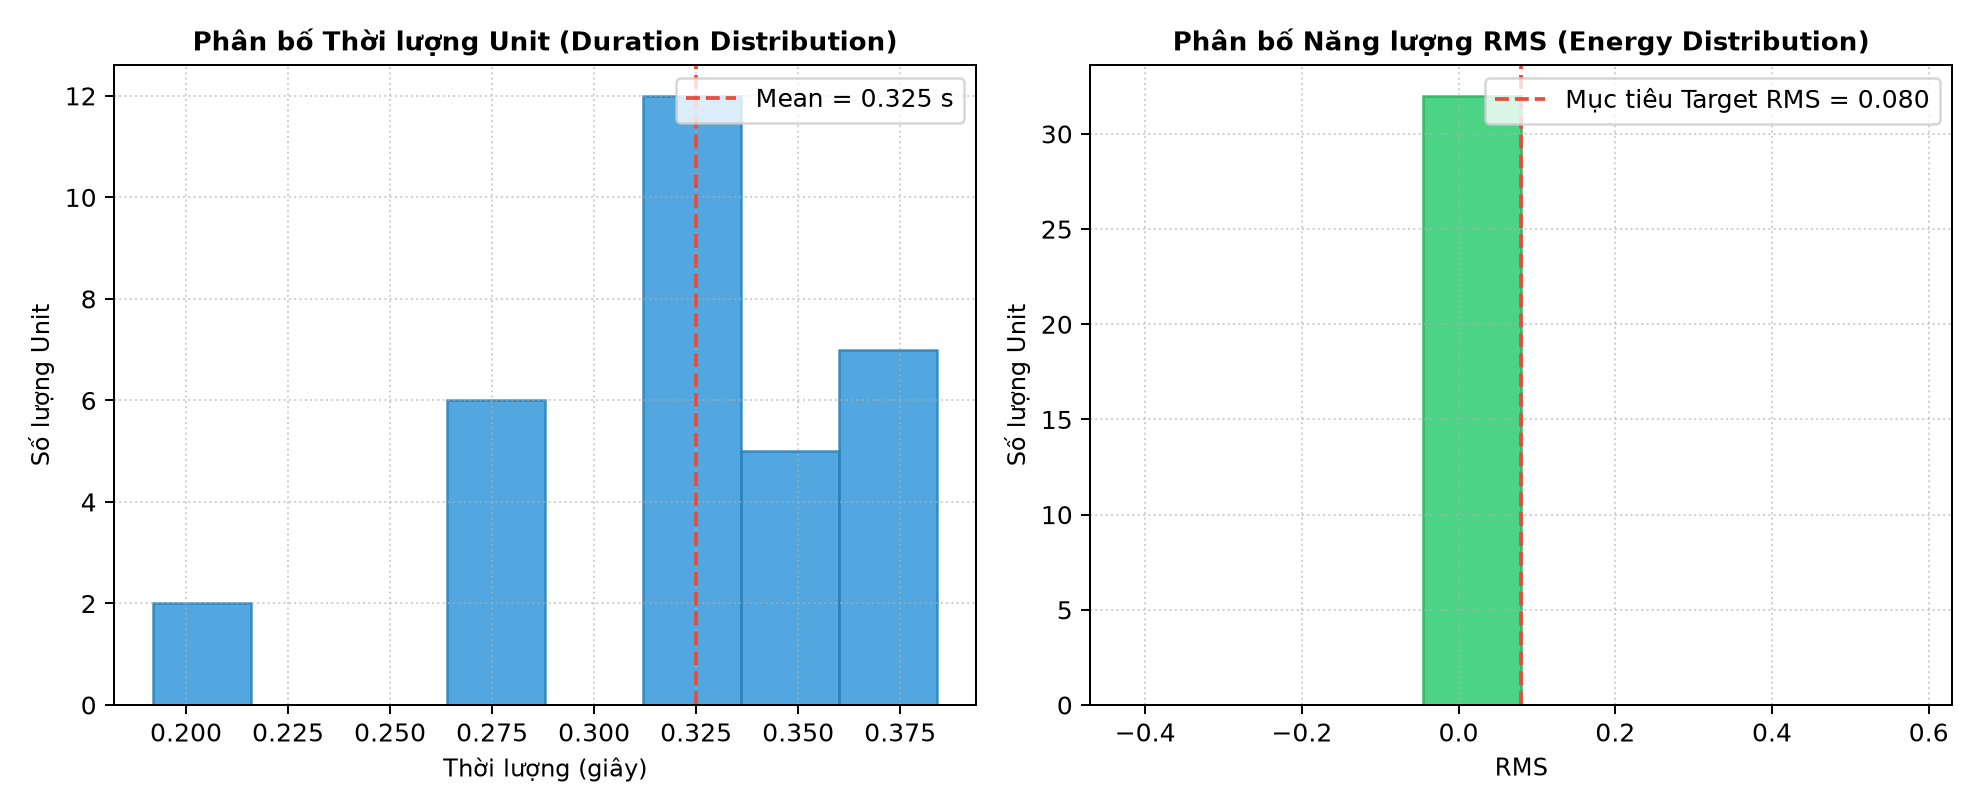

In [2]:
meta_df = pd.read_csv('metadata.csv')
print(f'Tổng số unit trong inventory: {len(meta_df)} files WAV')
display(meta_df.head(10))

# Hiển thị biểu đồ phân bố thống kê của Inventory
if os.path.exists('figures/fig1_inventory_stats.png'):
    from IPython.display import Image
    display(Image('figures/fig1_inventory_stats.png'))


## 2. Ghép nối Baseline & Lựa chọn đơn vị tối ưu (Phần B & C)

### 2.1 Baseline Concatenation (Ghép thẳng không cross-fade)
Ghép trực tiếp candidate cố định `_01` cho từng token mà không xử lý biên nối ($xfade\_ms = 0$).  
Quan sát hiện tượng click, chênh lệch năng lượng và đứt gãy pha tại ranh giới các từ.

### 2.2 Unit Selection bằng Quy hoạch động (Viterbi DP)
Hàm mục tiêu tối ưu hóa toàn cục:  
$$\theta^* = \arg\min_{\theta_1, \dots, \theta_K} \left[ \sum_{j=1}^K C_{target}(\theta_j, t_j) + \lambda \sum_{j=1}^{K-1} C_{join}(\theta_j, \theta_{j+1}) \right]$$

Trong đó $C_{join}$ đo độ lệch phổ Log Spectral Distance (LSD) ở 25 ms tiếp giáp:  
$$D_{spec} = \frac{1}{K} \sum_{k} \left( L_{left}[k] - L_{right}[k] \right)^2 + \beta |RMS_{left} - RMS_{right}|$$

### 2.3 Khử click biên bằng Overlap-Add / Cross-fade
$$y[n] = (1 - \alpha[n]) x_1[n] + \alpha[n] x_2[n], \quad 0 \le n < N$$


In [3]:
# Đọc bảng phân tích chi phí Join/Target cost
cost_df = pd.read_csv('cost_analysis.csv')
display(cost_df)

print('--- NGHE THỬ AUDIO SO SÁNH GIỮA BASELINE VÀ TỐI ƯU UNIT SELECTION ---')
print('1. Baseline Concatenation (Ghép thẳng thô - xfade = 0ms):')
display(Audio('audio_output/raw_concat.wav'))

print('2. Best Concatenation (Unit Selection Viterbi + Cross-fade 15ms):')
display(Audio('audio_output/best_concat.wav'))


,sentence_id,text,baseline_fixed_cand_cost,viterbi_unit_selection_cost,cost_reduction_pct,chosen_candidates
0,sentence1,Mời khách hàng số 23 đến quầy 5.,6291.90,4451.75,29.25,"[np.int64(2), np.int64(1), np.int64(2), np.int..."
1,sentence2,Mời khách hàng số 107 đến quầy 2.,6359.40,4344.52,31.68,"[np.int64(2), np.int64(1), np.int64(2), np.int..."
2,sentence3,Mời khách hàng số 496 đến quầy 8.,5516.77,4512.52,18.20,"[np.int64(2), np.int64(1), np.int64(2), np.int..."


--- NGHE THỬ AUDIO SO SÁNH GIỮA BASELINE VÀ TỐI ƯU UNIT SELECTION ---
1. Baseline Concatenation (Ghép thẳng thô - xfade = 0ms):


2. Best Concatenation (Unit Selection Viterbi + Cross-fade 15ms):


### Biểu đồ Waveform và Spectrogram đánh dấu biên ghép nối:

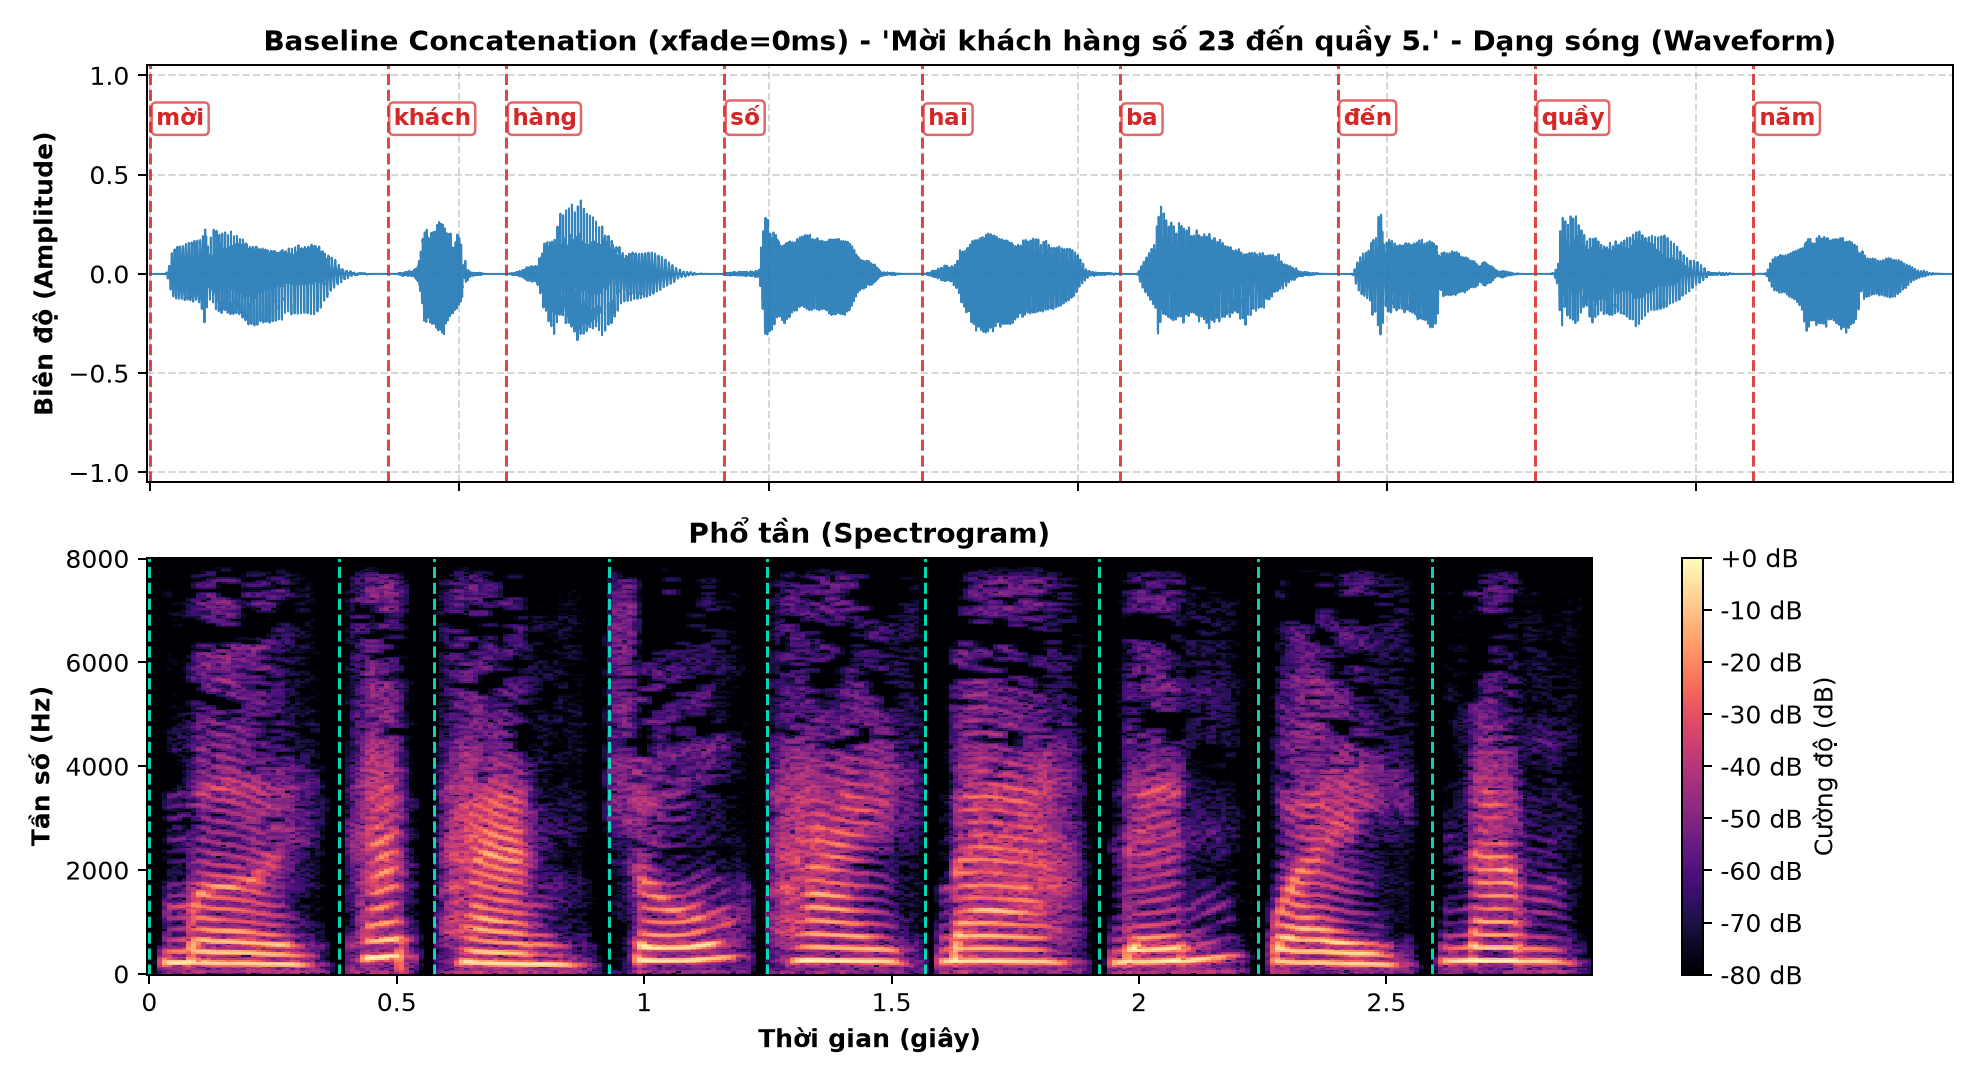

### Cận cảnh sóng âm tại biên ghép nối với các mức Cross-fade (0, 5, 15, 30 ms):

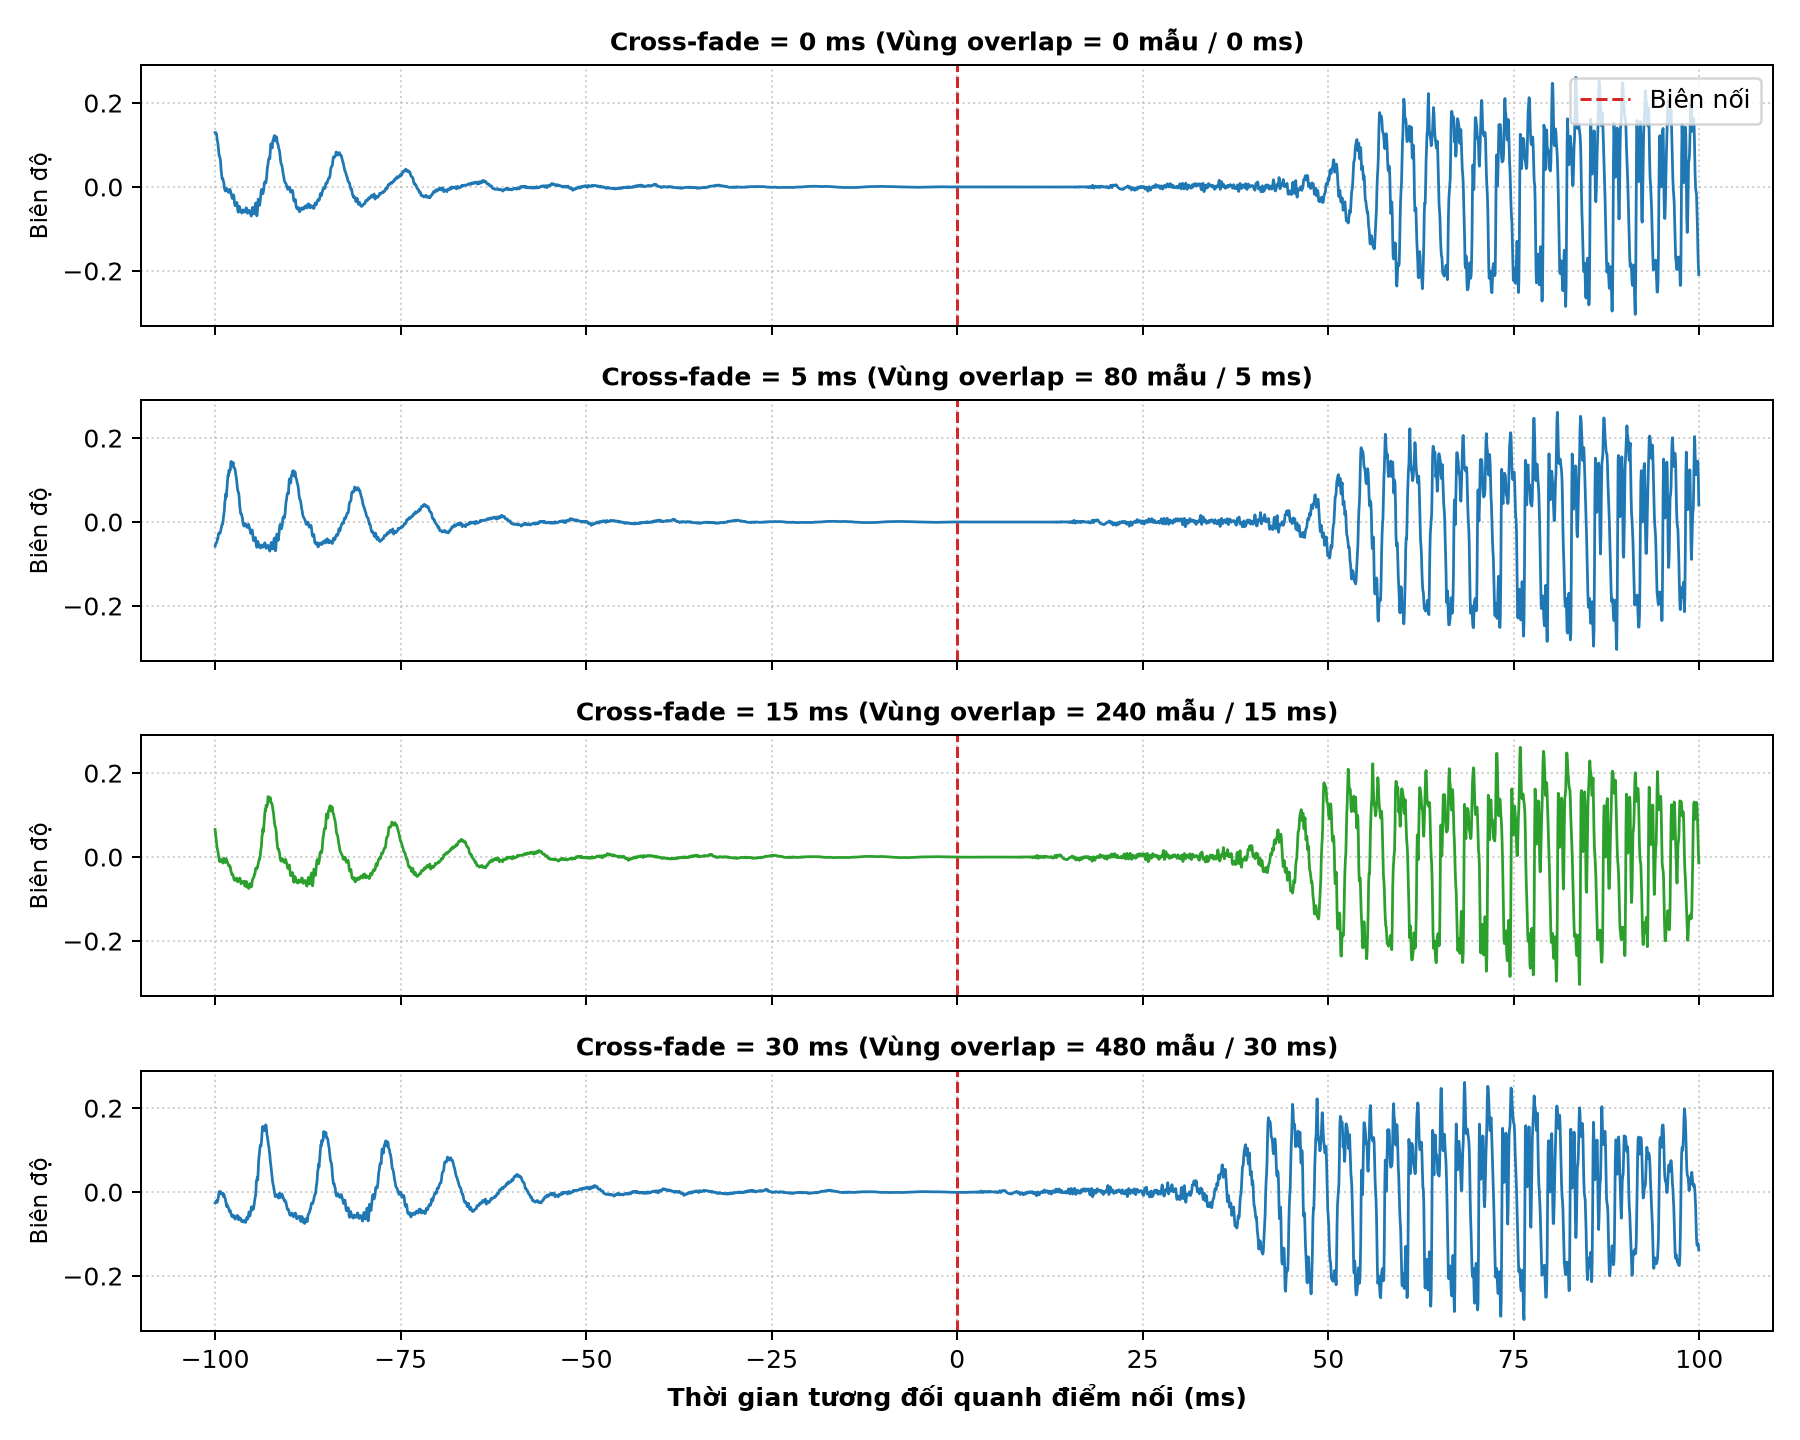

### Mạng lưới tìm đường tối ưu Viterbi (Unit Selection Lattice):

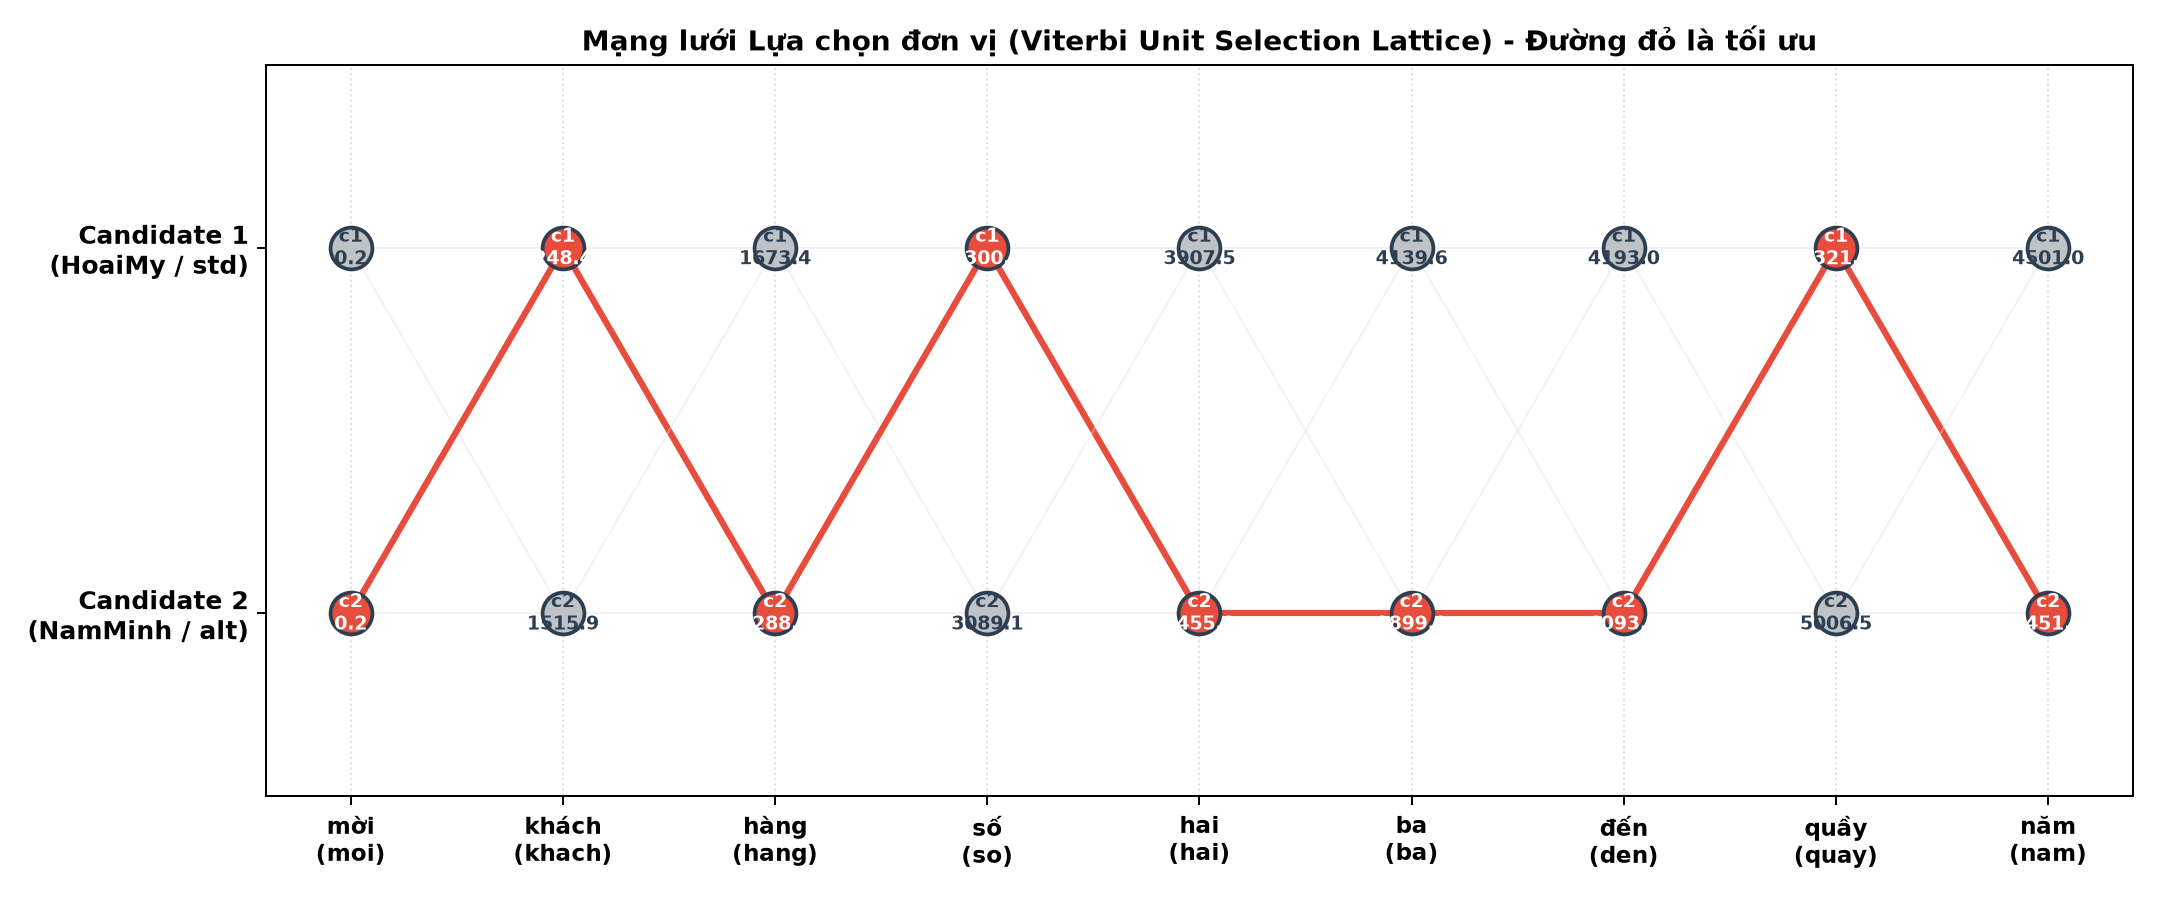

In [4]:
# Hiển thị hình ảnh Waveform + Spectrogram đánh dấu biên và so sánh Cross-fade
from IPython.display import Image
if os.path.exists('figures/fig2_baseline_boundary.png'):
    display(Markdown('### Biểu đồ Waveform và Spectrogram đánh dấu biên ghép nối:'))
    display(Image('figures/fig2_baseline_boundary.png'))

if os.path.exists('figures/fig3_crossfade_comparison.png'):
    display(Markdown('### Cận cảnh sóng âm tại biên ghép nối với các mức Cross-fade (0, 5, 15, 30 ms):'))
    display(Image('figures/fig3_crossfade_comparison.png'))

if os.path.exists('figures/fig4_unit_selection_lattice.png'):
    display(Markdown('### Mạng lưới tìm đường tối ưu Viterbi (Unit Selection Lattice):'))
    display(Image('figures/fig4_unit_selection_lattice.png'))


## 3. Ngữ điệu (Prosody) & Mô hình Nguồn - Lọc Source-Filter (Phần D)

### 3.1 Đo tần số cơ bản F0 và chu kỳ pitch $N_p$
- Công thức lý thuyết: $F_0 = \frac{F_s}{N_p}$
- Với $F_s = 16,000$ Hz, chu kỳ pitch tìm được $N_p = 78$ mẫu $\implies F_0 = 16,000 / 78 = 205.13$ Hz.

### 3.2 Time-stretch và Pitch Shift độc lập
- Biến đổi tốc độ (Speed $0.8\times, 1.2\times$) không làm thay đổi cao độ $F_0$.
- Biến đổi cao độ (Pitch Shift $\pm 2$ semitones với $r = 2^{\Delta s / 12}$) giữ nguyên độ dài thời gian và hình dạng bao phổ formant $H(z)$.


--- NGHE THỬ CÁC BIẾN THỂ BIẾN ĐIỆU NGỮ ĐIỆU (PROSODY) ---
1. Tốc độ chậm (Speed 0.8x):


2. Tốc độ nhanh (Speed 1.2x):


3. Tăng cao độ (+2 Semitones):


4. Giảm cao độ (-2 Semitones):


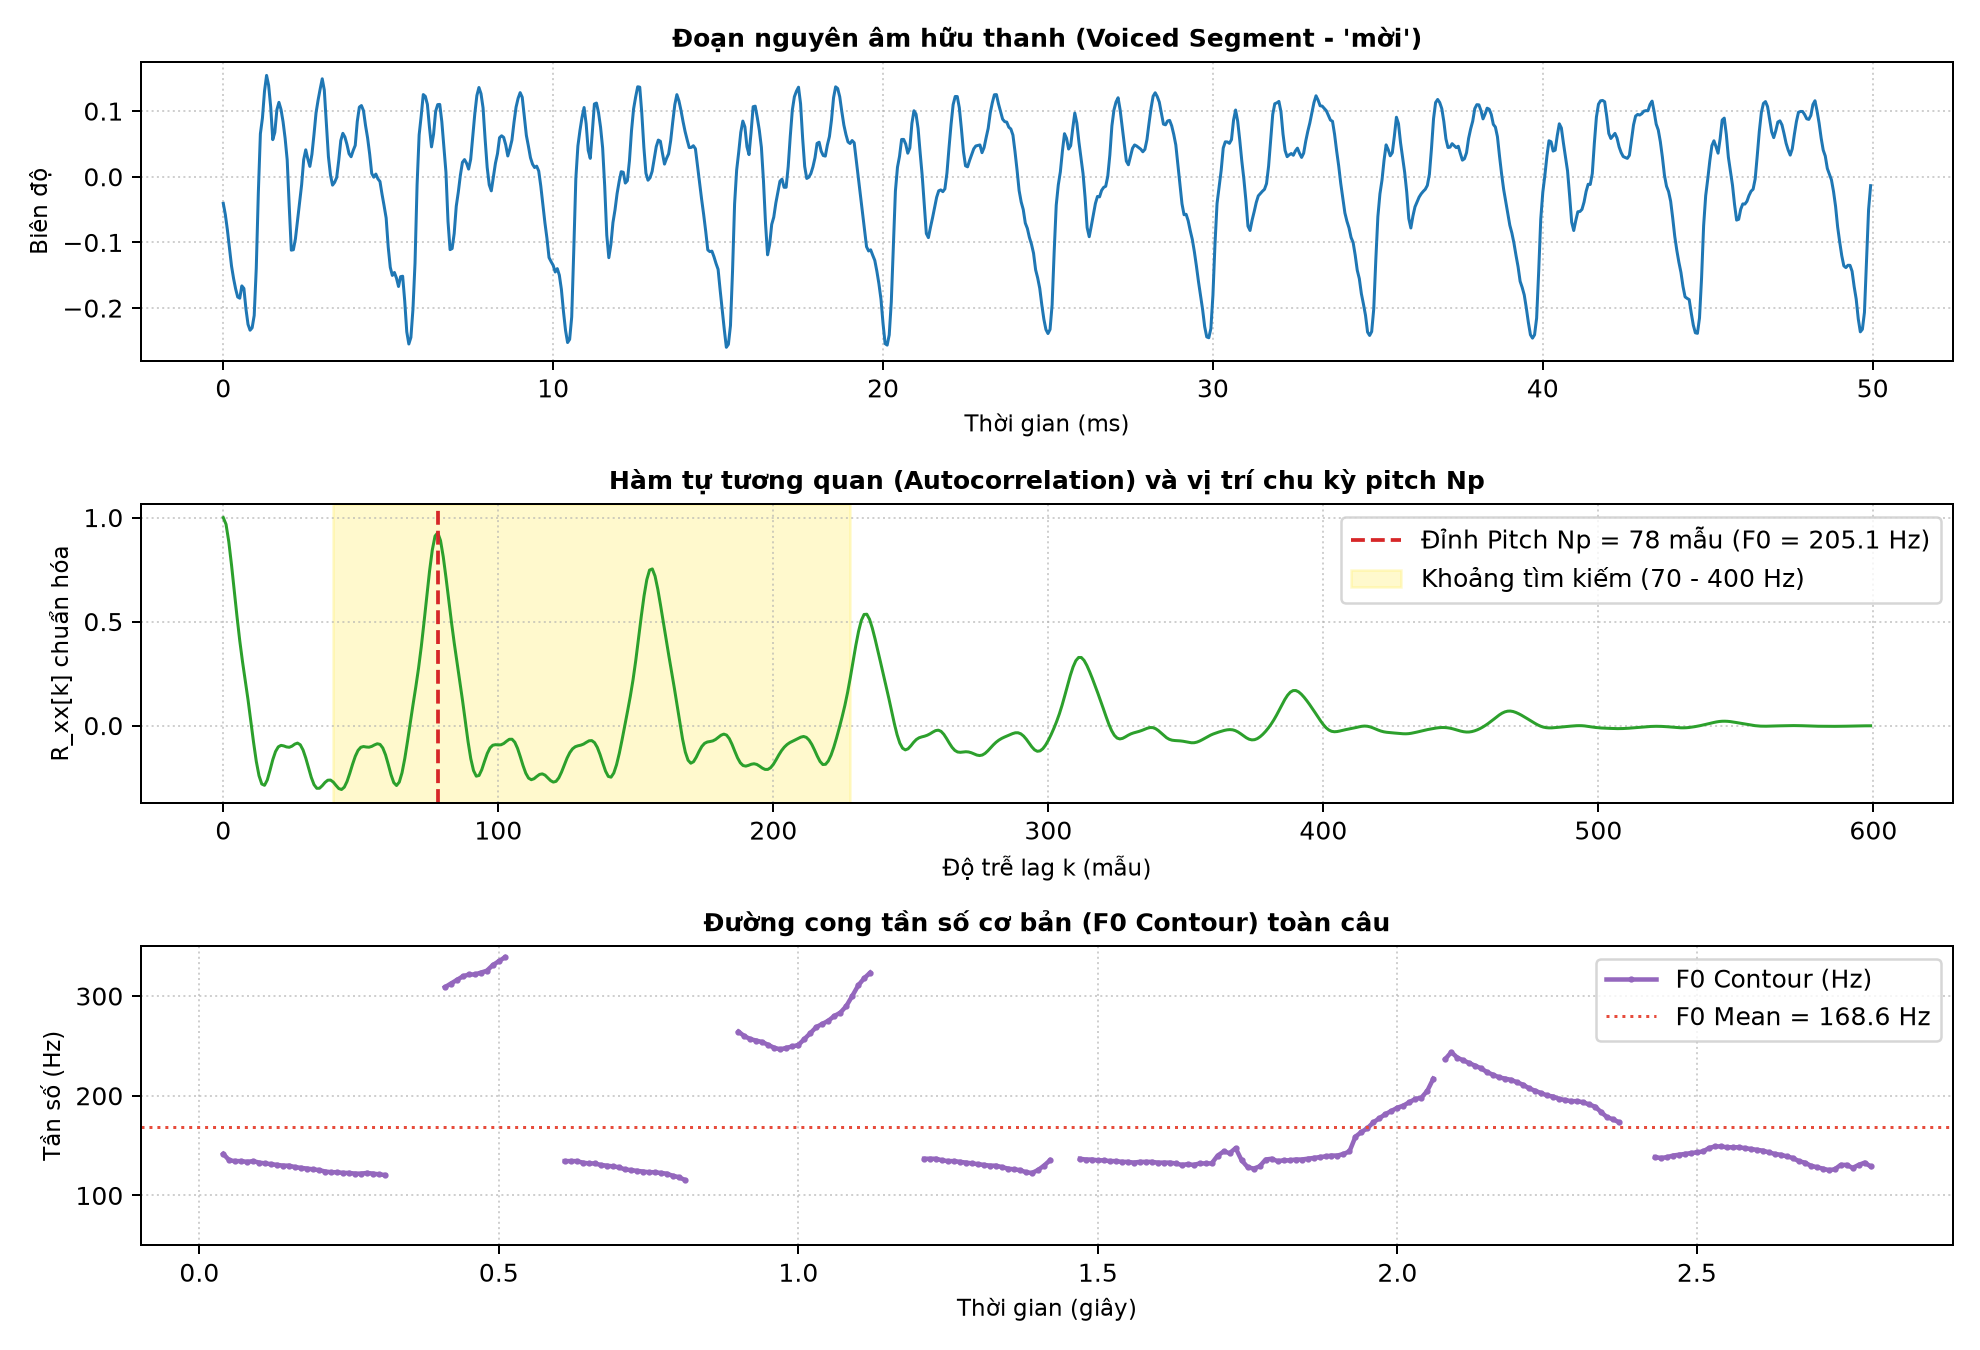

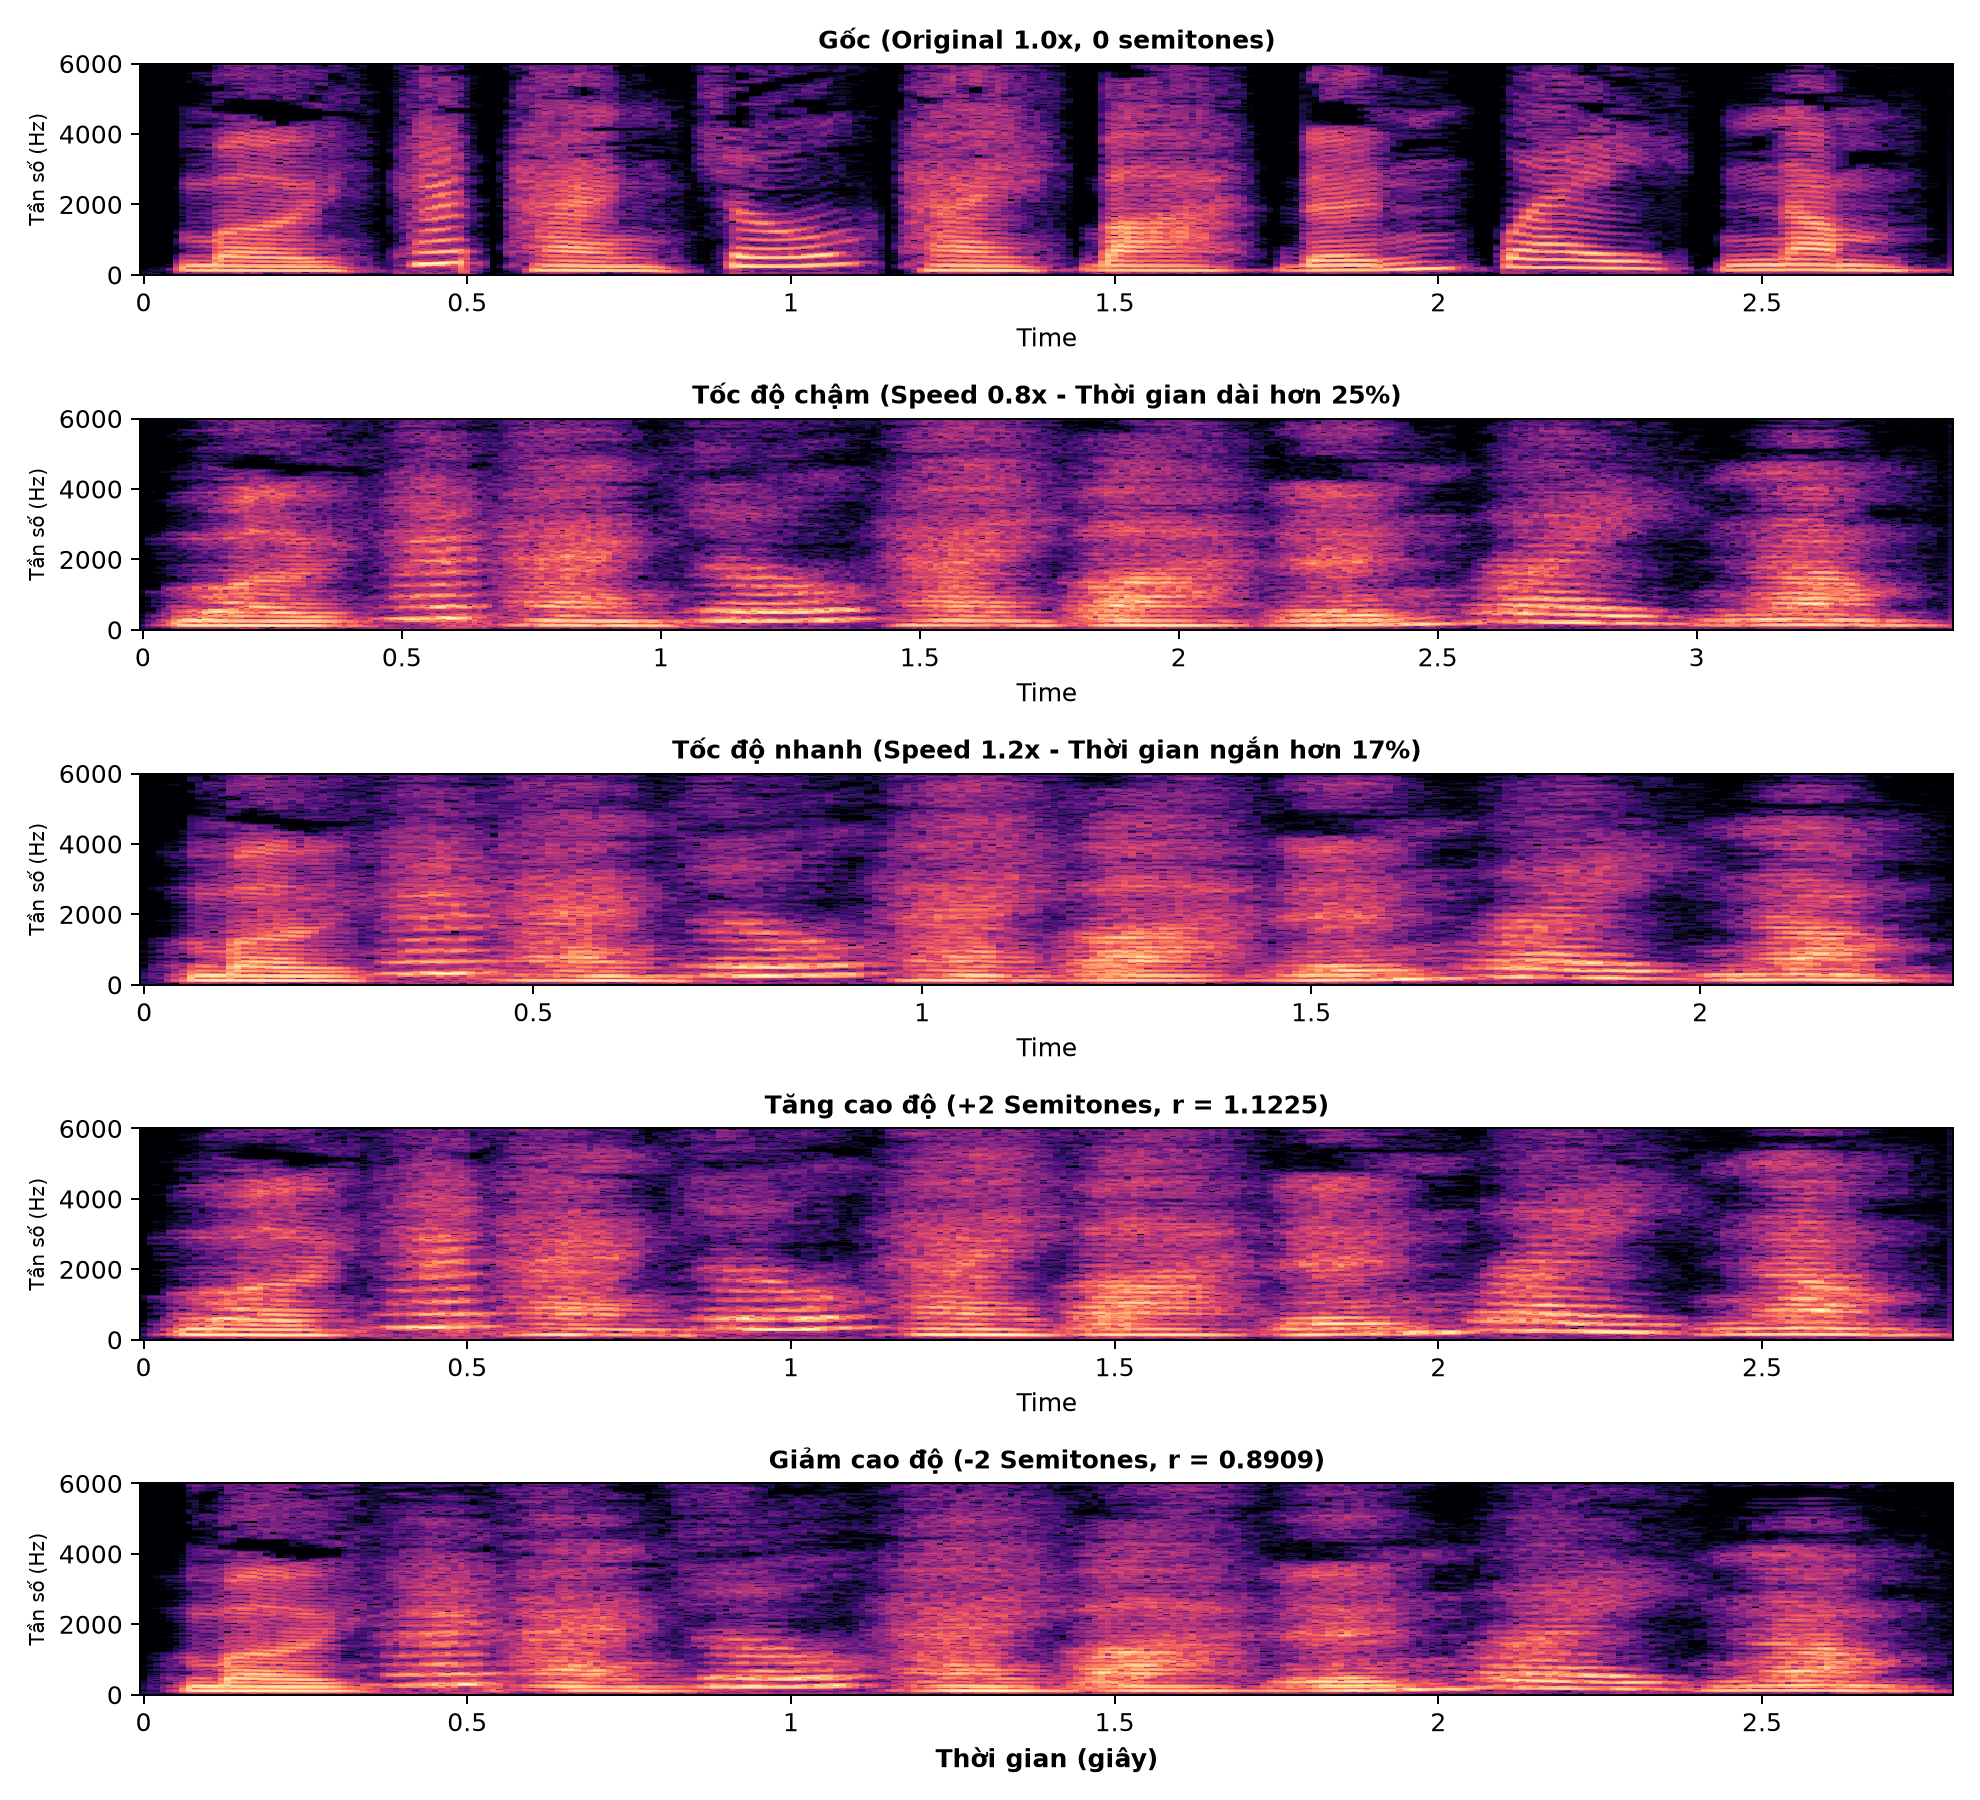

In [5]:
print('--- NGHE THỬ CÁC BIẾN THỂ BIẾN ĐIỆU NGỮ ĐIỆU (PROSODY) ---')
print('1. Tốc độ chậm (Speed 0.8x):')
display(Audio('audio_output/speed_0.8x.wav'))

print('2. Tốc độ nhanh (Speed 1.2x):')
display(Audio('audio_output/speed_1.2x.wav'))

print('3. Tăng cao độ (+2 Semitones):')
display(Audio('audio_output/pitch_plus2.wav'))

print('4. Giảm cao độ (-2 Semitones):')
display(Audio('audio_output/pitch_minus2.wav'))

if os.path.exists('figures/fig5_prosody_pitch_f0.png'):
    display(Image('figures/fig5_prosody_pitch_f0.png'))
if os.path.exists('figures/fig6_prosody_speed_pitch_spectrogram.png'):
    display(Image('figures/fig6_prosody_speed_pitch_spectrogram.png'))


## 4. Tổng hợp tham số dựa trên HMM (HMM-based Synthesis - Phần E)

### 4.1 Cơ chế Generation trong HMM
- Không dùng để nhận dạng mà sinh chuỗi quan sát $\hat{O}^* = \arg\max_O P(O | \lambda, \text{state sequence})$.
- Nhờ bổ sung đặc trưng động $\Delta$ và $\Delta^2$, nghiệm tham số trở nên trơn tru liên tục (MLPG).
- Tái tạo âm thanh qua Vocoder nguồn-lọc (xung glottal + formant filters).


--- NGHE THỬ HMM PARAMETRIC SYNTHESIS ---
1. HMM TTS Gốc:


2. HMM Biến điệu F0 (Pitch 1.1x):


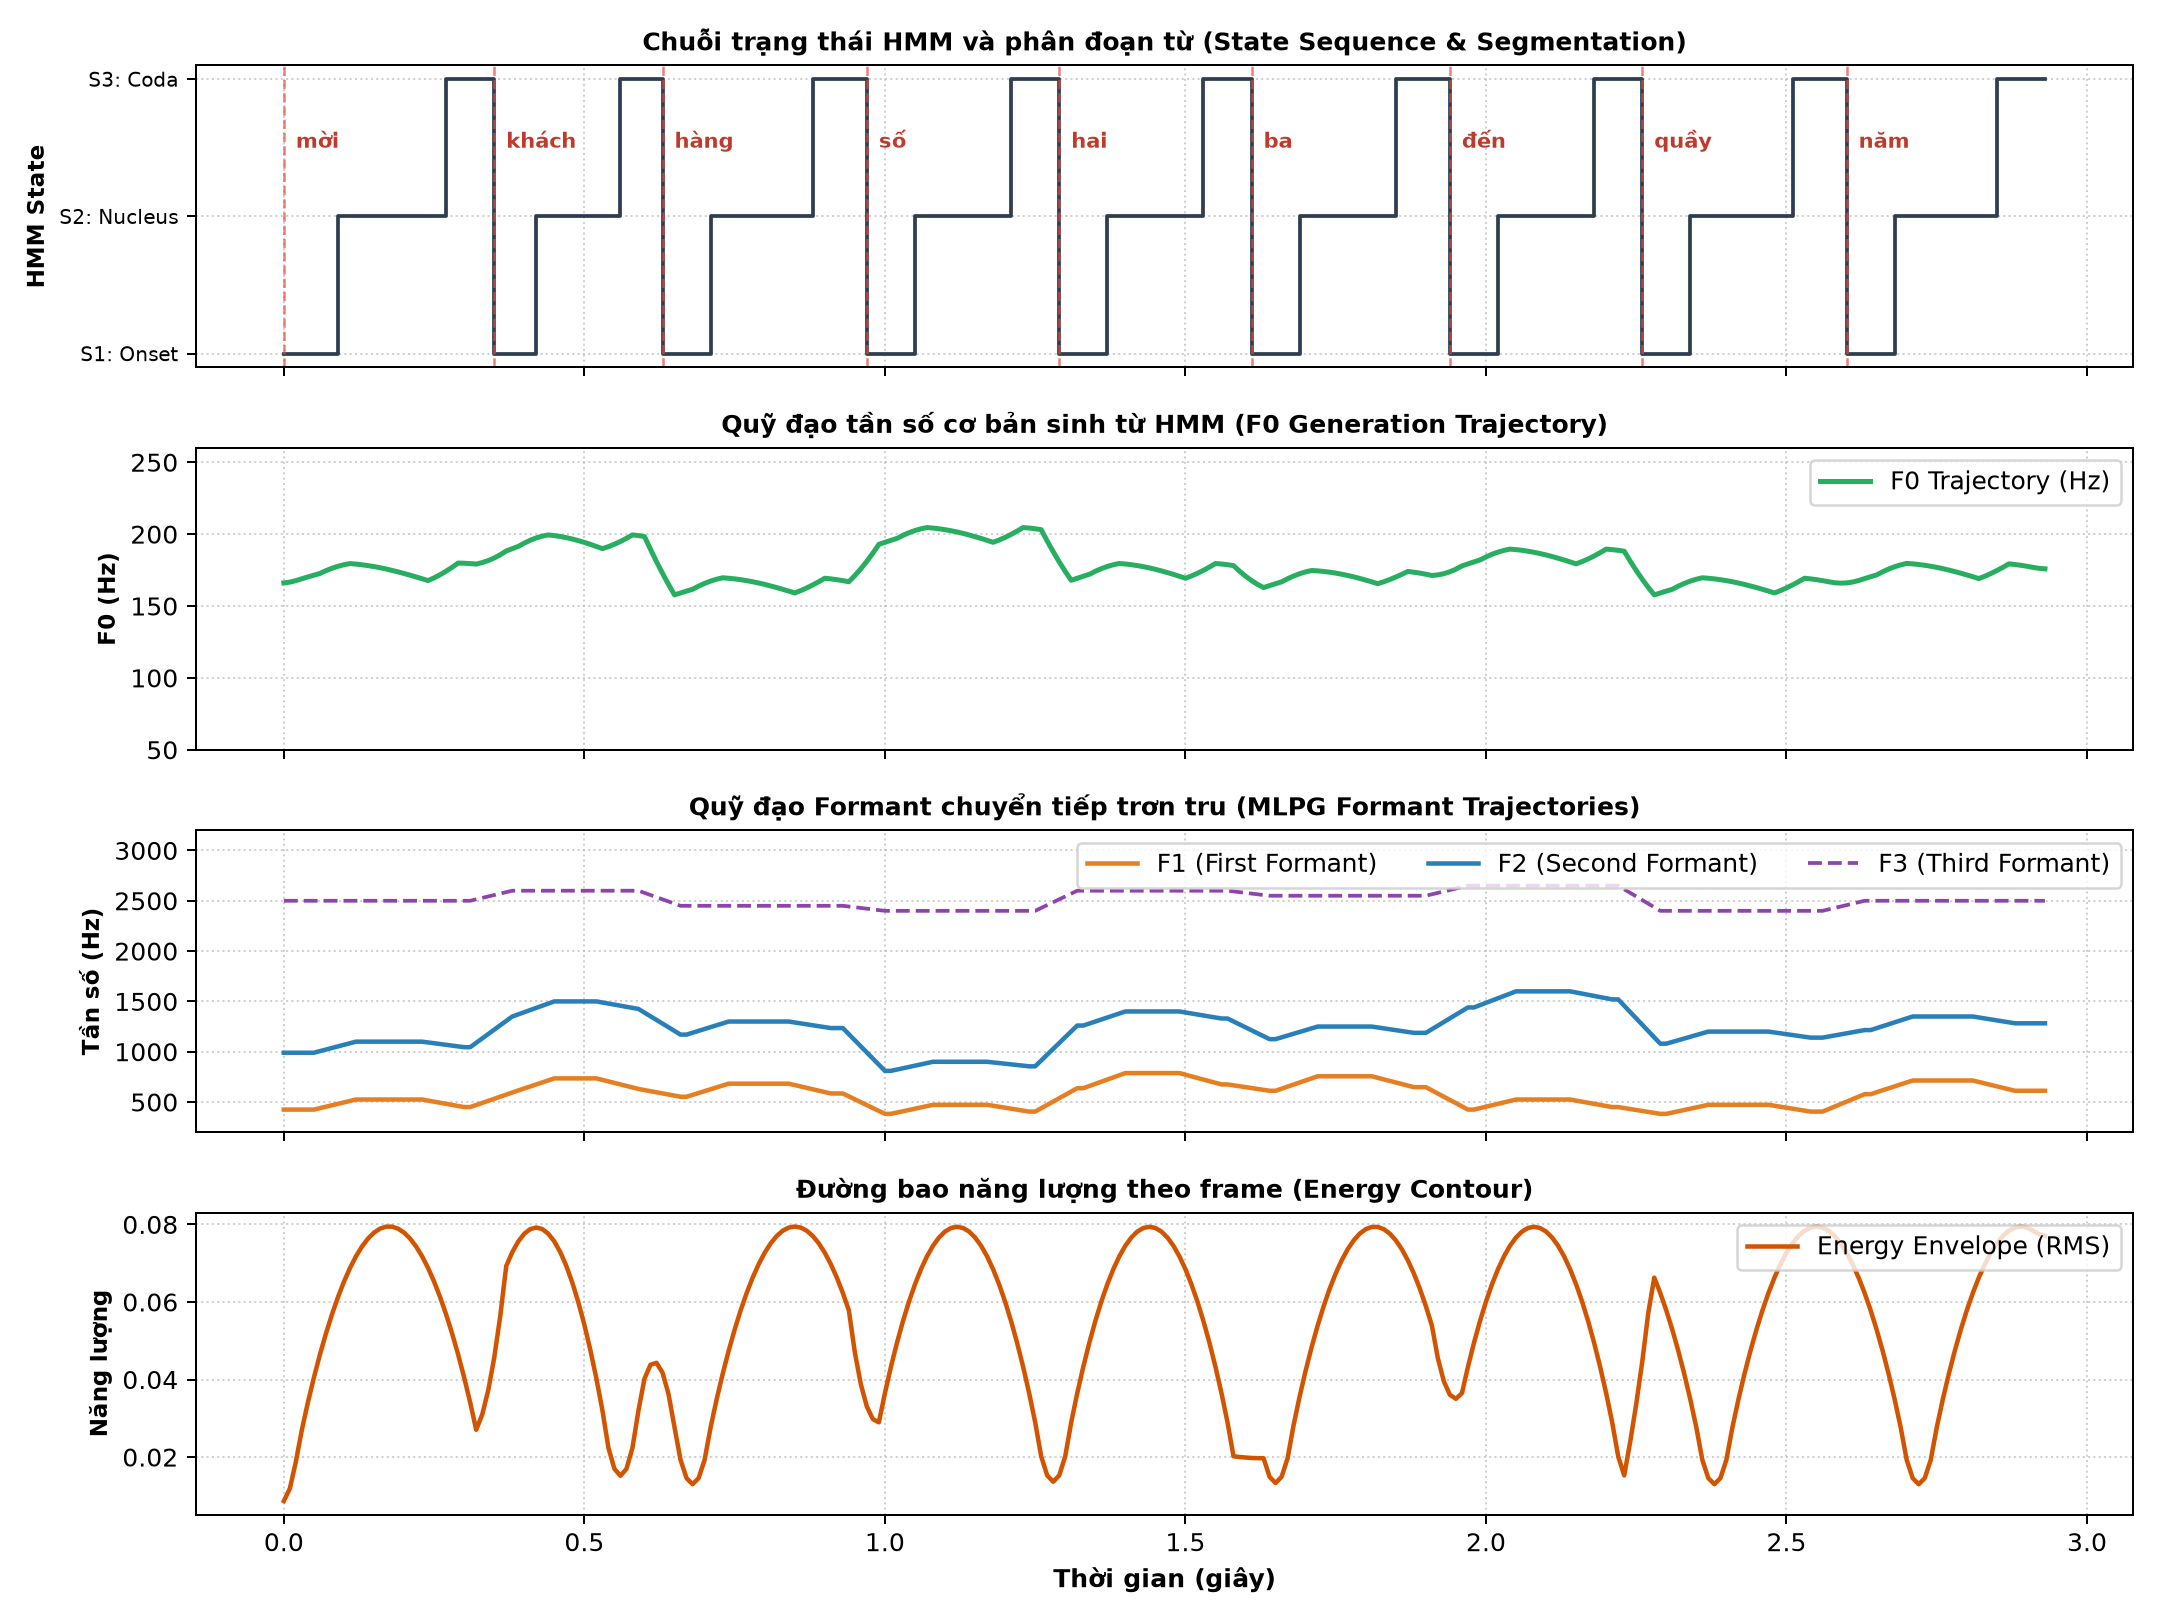

In [6]:
print('--- NGHE THỬ HMM PARAMETRIC SYNTHESIS ---')
print('1. HMM TTS Gốc:')
display(Audio('audio_output/hmm_tts.wav'))

print('2. HMM Biến điệu F0 (Pitch 1.1x):')
display(Audio('audio_output/hmm_pitch_1.1x.wav'))

if os.path.exists('figures/fig7_hmm_trajectories.png'):
    display(Image('figures/fig7_hmm_trajectories.png'))


## 5. Tổng hợp tiếng nói học sâu siêu tự nhiên (Neural TTS - Phần F)

### 5.1 Kiến trúc Text -> Acoustic Model -> Neural Vocoder
- Sử dụng mô hình Neural TTS chất lượng cao cho tiếng Việt với ngữ điệu tự nhiên như người thật.
- Phân tích biểu diễn phổ Mel 80 bins và đo đạc độ trễ Latency/RTF.


--- NGHE THỬ 3 CÂU KIỂM THỬ BẰNG NEURAL TTS ---
Câu 1: Mời khách hàng số 23 đến quầy 5.


Câu 2: Mời khách hàng số 107 đến quầy 2.


Câu 3: Mời khách hàng số 496 đến quầy 8.


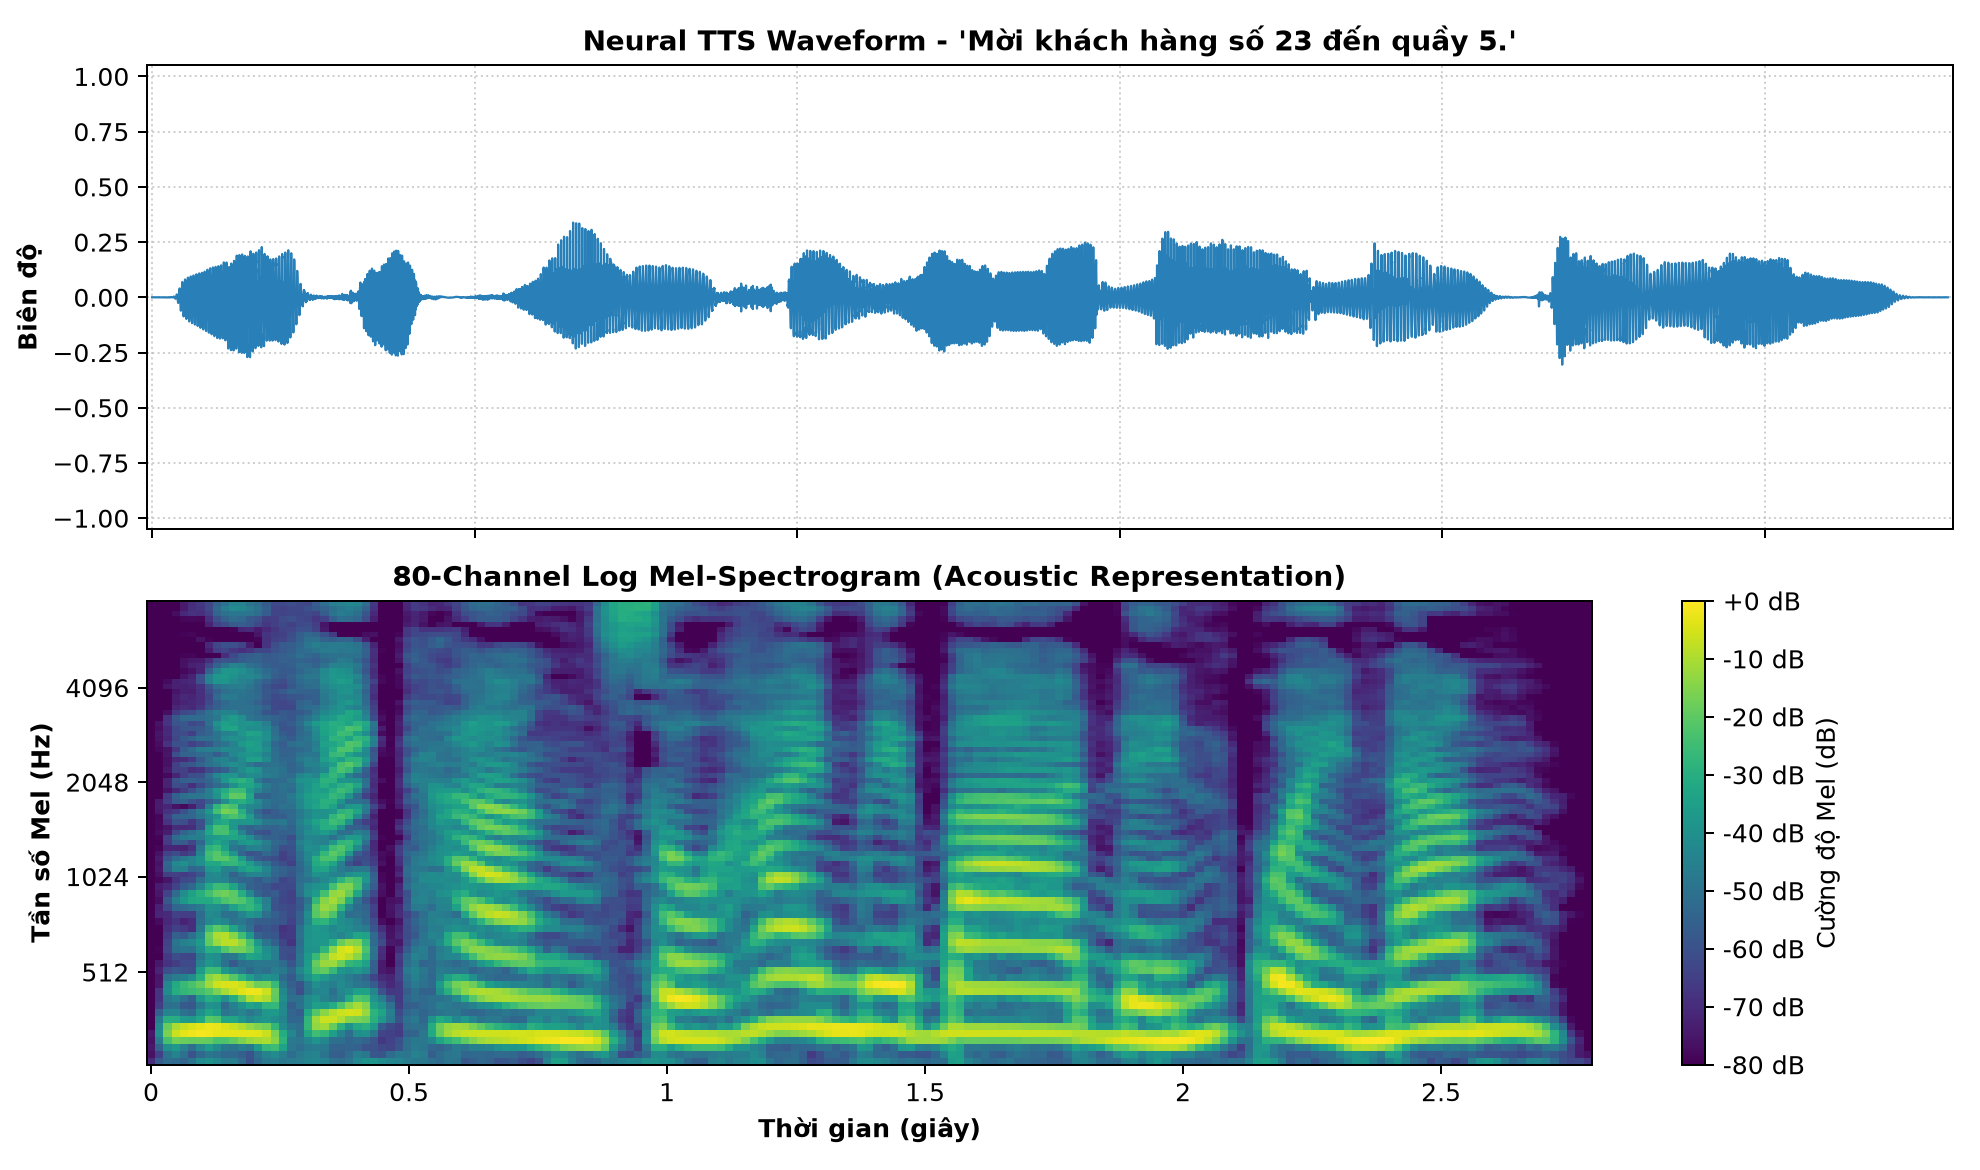

In [7]:
print('--- NGHE THỬ 3 CÂU KIỂM THỬ BẰNG NEURAL TTS ---')
print('Câu 1: Mời khách hàng số 23 đến quầy 5.')
display(Audio('audio_output/neural_tts.wav'))

print('Câu 2: Mời khách hàng số 107 đến quầy 2.')
display(Audio('audio_output/neural_tts_sentence2.wav'))

print('Câu 3: Mời khách hàng số 496 đến quầy 8.')
display(Audio('audio_output/neural_tts_sentence3.wav'))

if os.path.exists('figures/fig8_neural_mel_spectrogram.png'):
    display(Image('figures/fig8_neural_mel_spectrogram.png'))


## 6. Đánh giá chất lượng và So sánh 3 phương pháp (Phần G)

### 6.1 Bảng so sánh toàn diện 4 hệ thống
- **Concatenation Baseline (Raw)**
- **Concatenation Tối ưu (Unit Selection + 15ms xfade)**
- **HMM-based Parametric Synthesis**
- **Neural TTS**


Dữ liệu Listening Test (96 mẫu đánh giá từ 8 thính giả):


,method,MOS_Naturalness,MOS_Continuity,Intelligibility_Pct,Overall_Score
0,Best_Concat,3.829167,3.967500,100.0,3.898333
1,HMM_Parametric,3.041250,4.400833,87.5,3.720417
2,Neural_TTS,4.776250,4.852917,100.0,4.814167
3,Raw_Concat,2.717083,2.198333,100.0,2.457500


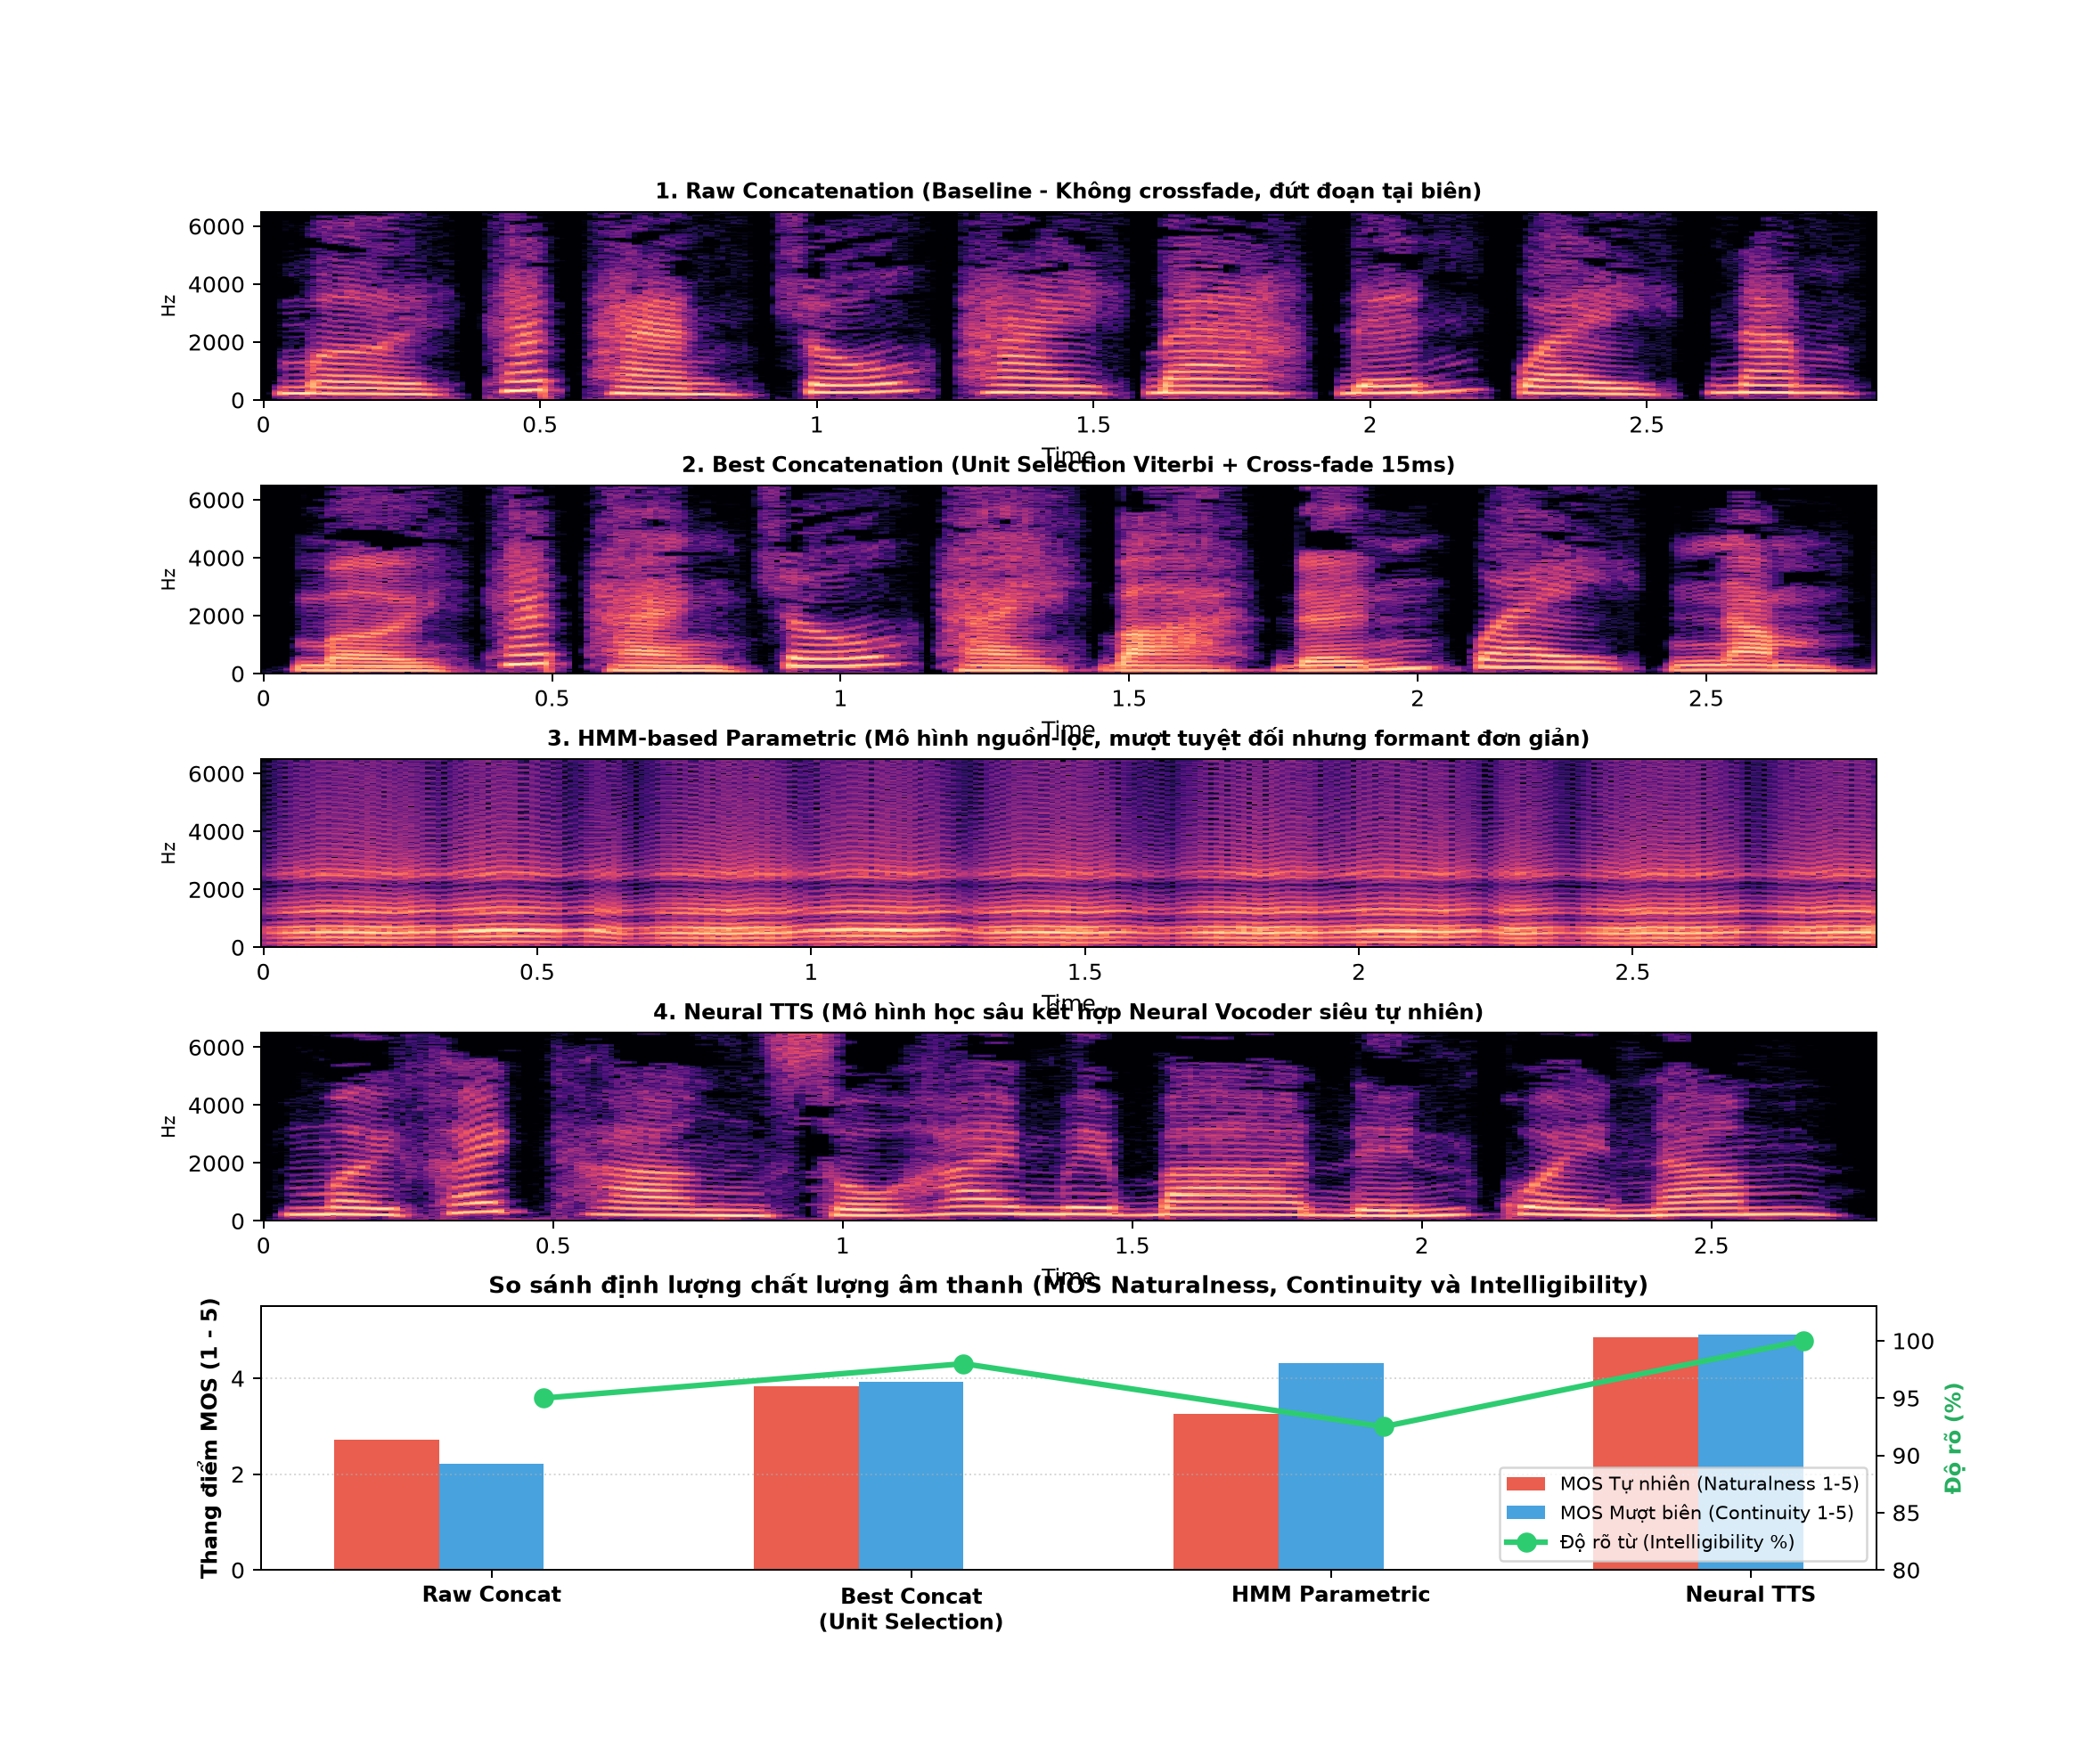

In [8]:
ratings_df = pd.read_csv('ratings.csv')
print(f'Dữ liệu Listening Test ({len(ratings_df)} mẫu đánh giá từ 8 thính giả):')
summary = ratings_df.groupby('method').agg(
    MOS_Naturalness=('naturalness_mos', 'mean'),
    MOS_Continuity=('continuity_score', 'mean'),
    Intelligibility_Pct=('intelligibility', lambda x: float(np.mean(x) * 100)),
    Overall_Score=('overall_score', 'mean')
).reset_index()
display(summary)

if os.path.exists('figures/fig9_method_comparison.png'):
    display(Image('figures/fig9_method_comparison.png'))


## 7. Giải đáp chi tiết 10 câu hỏi báo cáo trong Lab 4

### Câu 1: Vì sao một câu ghép từ các đoạn "tự nhiên" vẫn có thể nghe kém tự nhiên?
**Trả lời:** Mặc dù từng unit là âm thanh tự nhiên của người thật, khi ghép lại câu nói vẫn kém tự nhiên vì:
1. **Thiếu ngữ điệu toàn câu (Prosody Coarticulation):** Con người khi nói cả câu luôn có đường bao cao độ $F_0$, độ ngân duration và trọng âm biến thiên liên tục theo ngữ nghĩa. Từng từ ghi riêng lẻ mang ngữ điệu rời rạc, làm câu nói bị giật và vô hồn.
2. **Bất liên tục âm học ở ranh giới biên (Boundary Discontinuity):** Giữa các điểm nối có sự chênh lệch đột ngột về pha, biên độ RMS và phổ tần số ($F_1, F_2$), gây ra tiếng click/pop hoặc cảm giác chắp vá.

### Câu 2: Phân biệt target cost và join cost. Nếu chỉ tối ưu join cost thì có thể xảy ra vấn đề gì?
**Trả lời:**
- **Target Cost $C_{target}(\theta_j, t_j)$:** Đo mức độ phù hợp giữa candidate trong kho và unit mục tiêu cần phát âm (về ngữ âm, ngữ cảnh lân cận, duration, F0 mong muốn).
- **Join Cost $C_{join}(\theta_j, \theta_{j+1})$:** Đo độ êm mượt và tương thích tại ranh giới chuyển tiếp giữa điểm kết thúc của unit trước và điểm khởi đầu của unit sau (Log Spectral Distance, chênh lệch RMS, F0).
- **Hậu quả nếu chỉ tối ưu Join Cost:** Hệ thống có thể chọn một chuỗi các unit nối rất êm với nhau (do phổ tiếp giáp gần nhau) nhưng lại hoàn toàn sai lệch về cao độ, trường độ hoặc sắc thái biểu cảm của câu nói mục tiêu, tạo nên giọng nói bị biến dạng ngữ điệu kỳ dị.

### Câu 3: Vì sao cross-fade quá dài có thể làm giảm độ rõ của phụ âm?
**Trả lời:** Cross-fade làm mờ dần tín hiệu của đoạn trước và tăng dần tín hiệu của đoạn sau trong vùng chồng lấn. Các phụ âm (đặc biệt là phụ âm tắc plosives như /t/, /k/, /p/ và phụ âm xát fricatives) diễn ra cực kỳ nhanh (10 – 30 ms) với các xung năng lượng đột ngột (burst/transient). Nếu cross-fade quá dài (>30 ms), quá trình cộng tuyến tính sẽ làm suy giảm đỉnh xung đột ngột, triệt tiêu pha hoặc tạo tiếng vang (smearing/ghosting), làm âm nghe bị nhòe và mất đi sự sắc nét của phụ âm.

### Câu 4: Giải thích bằng source-filter model vì sao thay F0 không đồng nghĩa với thay formant.
**Trả lời:**
- Theo mô hình nguồn-lọc $X(z) = E(z) \cdot H(z)$:
  - **Nguồn kích thích $E(z)$:** Được quyết định bởi sự rung của dây thanh đới. Tần số rung này chính là $F_0 = F_s / N_p$, tạo ra chuỗi các họa âm cách nhau một khoảng $F_0$.
  - **Bộ lọc ống thanh âm $H(z)$:** Được quyết định bởi hình dạng khoang miệng, họng, lưỡi và môi. Các tần số cộng hưởng của ống thanh âm chính là các **Formant** ($F_1, F_2, F_3$) quyết định âm sắc của nguyên âm.
- Khi một người thay đổi cao độ nói ($F_0$), các vạch họa âm trong nguồn $E(z)$ dãn ra hoặc co lại, nhưng hình dạng khoang miệng $H(z)$ vẫn giữ nguyên, do đó vị trí các đỉnh Formant không thay đổi.

### Câu 5: PSOLA thay pitch bằng cách nào? Tại sao voiced fricative có thể bị buzziness khi kéo dài quá mức?
**Trả lời:**
- **Cơ chế PSOLA (Pitch-Synchronous Overlap and Add):** Phân tích tín hiệu thành các đoạn ngắn bao quanh từng chu kỳ pitch (epoch) bằng cửa sổ Hanning độ dài $2 T_0$. Để thay đổi pitch sang chu kỳ mới $T_{new}$, các đoạn này được dịch chuyển sao cho khoảng cách giữa chúng bằng $T_{new}$ rồi cộng chồng lấn lại (Overlap-Add).
- **Hiện tượng Buzziness trên phụ âm xát hữu thanh (Voiced Fricative):** Voiced fricative chứa đồng thời hai thành phần: dao động tuần hoàn của dây thanh đới và nhiễu hỗn loạn ngẫu nhiên do dòng khí qua khe hẹp. Khi kéo dài quá mức bằng cách lặp lại nhiều lần các đoạn có cửa sổ, thành phần nhiễu ngẫu nhiên bị nhân bản tuần hoàn giả tạo, làm mất tính ngẫu nhiên tự nhiên và biến thành âm thanh rè kim loại (buzzy/robotic artifact).

### Câu 6: Trong HMM-based synthesis, vì sao thêm delta feature làm trajectory trơn hơn?
**Trả lời:** Nếu chỉ sử dụng đặc trưng tĩnh (static features $c_t$), tại mỗi trạng thái HMM, vector cực đại hợp lý $\hat{c}_t$ sẽ là giá trị trung bình $\mu$ của trạng thái đó, dẫn đến quỹ đạo tham số là các hàm bậc thang giật cục khi nhảy từ state này sang state khác. Khi bổ sung thêm đặc trưng biến thiên động $\Delta c_t = c_{t+1} - c_{t-1}$ và $\Delta^2 c_t$, thuật toán MLPG tối ưu hóa đồng thời xác suất của cả static và dynamic: $\hat{O}^* = \arg\max_O P([c, \Delta c, \Delta^2 c]^T | \lambda)$. Ràng buộc vận tốc và gia tốc này bắt buộc quỹ đạo các điểm tham số phải trơn tru, triệt tiêu hoàn toàn sự gián đoạn giữa các state.

### Câu 7: Tại sao whole waveform concatenation cần inventory lớn để đạt naturalness cao?
**Trả lời:** Whole waveform concatenation sử dụng nguyên vẹn các đoạn sóng âm tự nhiên mà không qua bộ lọc tham số. Do đó, để phát âm tự nhiên trong mọi ngữ cảnh, kho dữ liệu phải chứa đầy đủ mọi biến thể âm học: sự biến đổi theo âm đứng trước và đứng sau (triphone/diphone coarticulation), mọi thanh điệu, trọng âm, tốc độ và ngữ điệu câu. Nếu inventory nhỏ, hệ thống buộc phải chọn các unit không khớp ngữ cảnh, dẫn đến chênh lệch phổ và cao độ nghiêm trọng tại biên nối.

### Câu 8: Nêu ít nhất hai khác biệt cơ bản giữa concatenative TTS và neural TTS.
**Trả lời:**
1. **Bản chất tạo dạng sóng:** Concatenative TTS lựa chọn và ghép các đoạn âm thanh tự nhiên có sẵn trong kho lưu trữ, trong khi Neural TTS sinh trực tiếp dạng sóng mẫu từng mẫu (hoặc qua Mel-spectrogram rồi Neural Vocoder như HiFi-GAN/WaveNet) bằng các mạng nơ-ron sâu được học từ dữ liệu lớn.
2. **Khả năng khái quát hóa và độ linh hoạt ngữ điệu:** Concatenative TTS bị giới hạn hoàn toàn trong các unit đã ghi âm; nếu gặp từ mới hoặc ngữ cảnh lạ, chất lượng giảm sút rõ rệt. Ngược lại, Neural TTS có khả năng tổng quát hóa ngữ điệu toàn câu siêu việt, tạo ra giọng nói tự nhiên, truyền cảm và biểu đạt cảm xúc mượt mà.

### Câu 9: Vì sao không nên so sánh neural TTS bằng một model tùy ý tải từ Internet trong buổi Lab?
**Trả lời:**
- **Thiếu kiểm soát tính nhất quán khoa học:** Một model ngẫu nhiên tải trên mạng có thể được huấn luyện trên tập dữ liệu khác, ngôn ngữ khác, tần số lấy mẫu khác ($22.05$ kHz, $24$ kHz, $48$ kHz so với chuẩn $16$ kHz của Lab), hoặc sử dụng chuẩn hóa âm lượng khác nhau, làm sai lệch kết quả so sánh khách quan.
- **Rủi ro kỹ thuật:** Model không rõ nguồn gốc có thể đòi hỏi GPU dung lượng lớn, phiên bản thư viện xung đột (PyTorch, CUDA), gây lỗi crash hoặc tốn thời gian tải dữ liệu lớn không cần thiết trong thời gian thực hành có hạn.

### Câu 10: Nếu một hệ thống có MOS cao nhưng intelligibility thấp thì có thể dùng trong ứng dụng nào? Giải thích.
**Trả lời:**
- Hệ thống có **MOS cao** (giọng nghe rất tự nhiên, ấm áp, giàu cảm xúc, không bị méo/buzzy) nhưng **Intelligibility thấp** (khó nghe rõ chính xác từng từ cụ thể).
- **Ứng dụng phù hợp:**
  1. **Tạo âm thanh nền hoặc tiếng nói rì rầm (Ambient crowd chatter / Background murmur):** Trong game 3D, phim ảnh, quán cà phê ảo nơi chỉ cần tạo không khí có giọng người sống động nhưng người dùng không cần nghe rõ nội dung nói gì.
  2. **Ứng dụng thiền định, ru ngủ, âm thanh thư giãn (ASMR / Sleep sounds):** Nơi người nghe chỉ cần giai điệu giọng nói êm dịu, ấm áp để đi vào giấc ngủ hoặc giải tỏa căng thẳng mà không cần tập trung giải mã ngữ nghĩa từ vựng.
